--- Automatically Generated Hierarchy ---
[('y1', 'setosa'), ('y1', 'y2'), ('y2', 'versicolor'), ('y2', 'virginica')]
-----------------------------------
Model Accuracy: 0.9933

Visualizing the model structure...


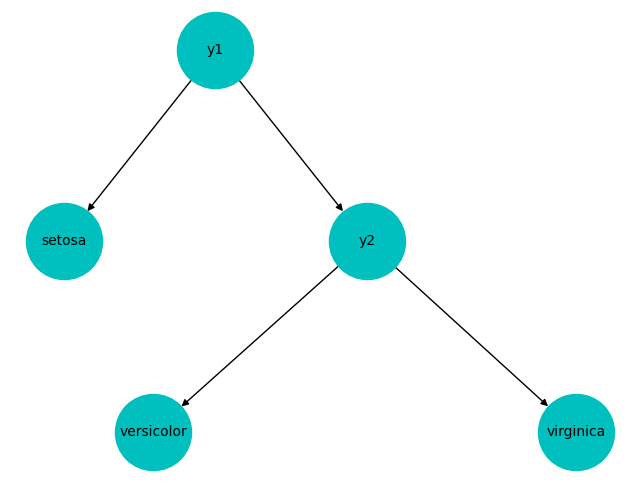


Visualizing the prediction path for the first sample...


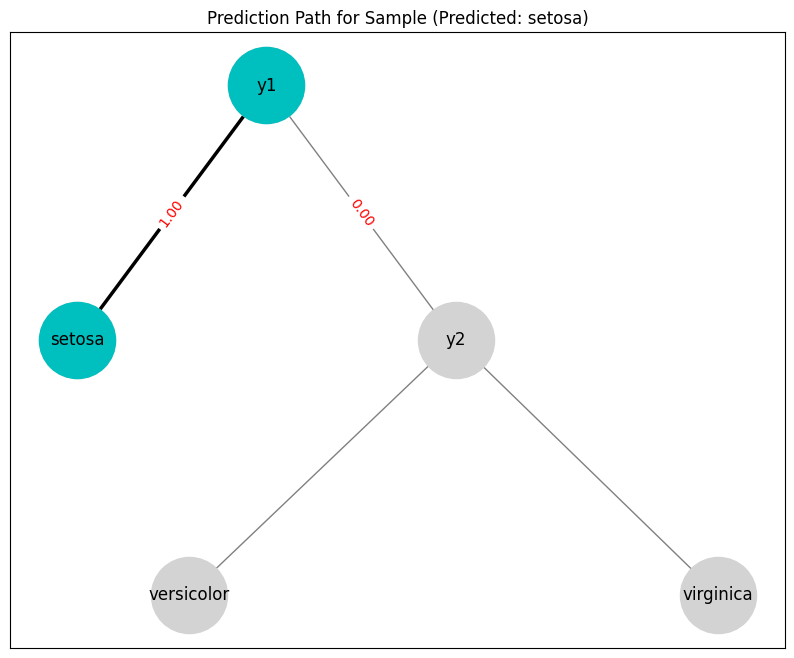

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from sklearn.utils.multiclass import unique_labels
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, to_tree
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from hierarchical_ensemble_classifier import HierarchicalEnsembleClassifier, HierarchyBuilder

# --- Example Usage ---

# 1. Load and prepare Iris data
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target_names[iris.target], name='species').astype(str)
X.columns = X.columns.str.replace(' (cm)', '').str.replace(' ', '_')

# 2. Build the hierarchy automatically
# Note: The iris classes are named '0', '1', '2' after conversion.
# This corresponds to setosa, versicolor, virginica.
# y_numeric = pd.Series(iris.target, name='species').astype(str)
builder = HierarchyBuilder(linkage_method='ward')
builder.fit(X, y)
hierarchy = builder.hierarchy_

print("--- Automatically Generated Hierarchy ---")
# The root node (e.g., 'y0') splits into its children.
# An intermediate node (e.g., 'y1') splits further.
# Leaf nodes ('0', '1', '2') are the final classes.
print(hierarchy.edges())
print("-" * 35)

# 3. Define estimators for the internal nodes of the hierarchy
# Find the internal (subclassifier) nodes from the generated graph
subclassifier_nodes = [n for n in hierarchy.nodes() if hierarchy.out_degree(n) > 0]
estimators = {
    'y1': {
            'classifier': DecisionTreeClassifier(random_state=42),
            'features': ['sepal_length', 'sepal_width'],
            },
    'y2': {
            'classifier': DecisionTreeClassifier(random_state=42),
            'features': ['petal_length', 'petal_width']},
    }

# 4. Initialize and fit the hierarchical classifier
hclf = HierarchicalEnsembleClassifier(hierarchy=hierarchy, estimators=estimators)
hclf.fit(X, y)

# 5. Make predictions and evaluate
y_pred = hclf.predict(X)
accuracy = accuracy_score(y, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# 6. Visualize the model and a prediction path
print("\nVisualizing the model structure...")
hclf.plot_model()

print("\nVisualizing the prediction path for the first sample...")
hclf.plot_prediction_paths(X.iloc[[0]])

In [4]:
cross_val_score(hclf, X, y, cv=5)  # Example cross-validation   

array([1.        , 0.93333333, 0.86666667, 0.93333333, 0.8       ])

In [5]:
hclf._root

'y1'

In [ ]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from hierarchical_ensemble_classifier import (
    HierarchyBuilder, 
    HierarchicalEnsembleClassifier,
)

# 1. Load and prepare Iris data using pandas
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target_names[iris.target], name='species').astype(str)
X.columns = X.columns.str.replace(' (cm)', '').str.replace(' ', '_')

## Building a Hierarchy

# Automatically build a hierarchy from class eigenprofiles
hb = HierarchyBuilder()
hb.fit(X, y)

# Inspect the generated hierarchy
hb.hierarchy_.edges() # .hierarchy_ is a networkx DiGraph and .Y_ is a pd.DataFrame of subclassifier classes
# OutEdgeView([('y1', 'setosa'), ('y1', 'y2'), ('y2', 'versicolor'), ('y2', 'virginica')])


OutEdgeView([('y1', 'setosa'), ('y1', 'y2'), ('y2', 'versicolor'), ('y2', 'virginica')])

Cross-validated accuracy: 0.9200 ± 0.0686


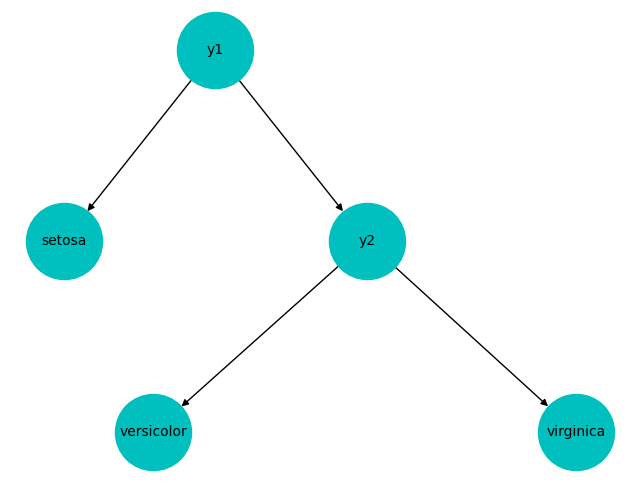

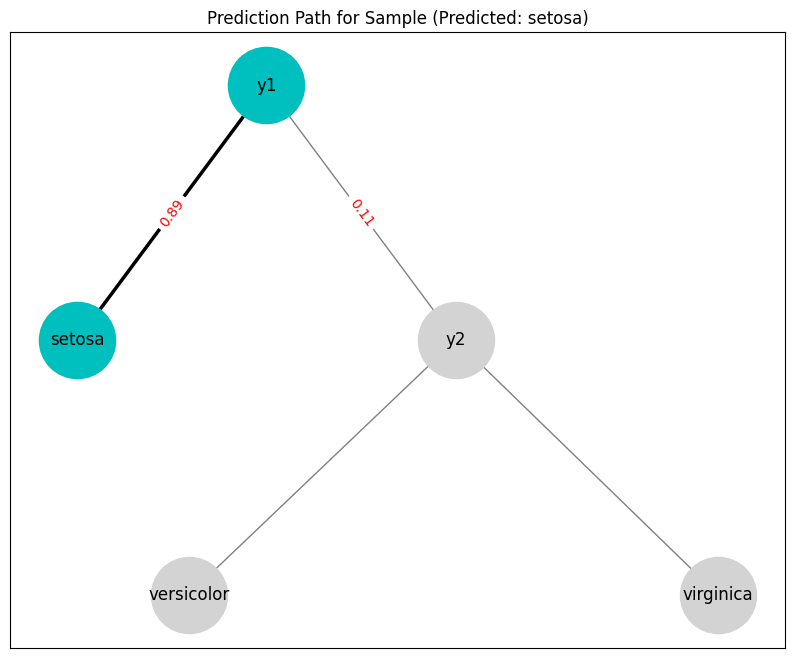

In [ ]:
## Training Hierarchical Classifiers

# Specify an estimator for each internal node in the hierarchy
estimators = {
    'y1': {
            'classifier': LogisticRegression(random_state=42),
            'features': ['sepal_length', 'sepal_width'],
            },
    'y2': {
            'classifier': DecisionTreeClassifier(random_state=42),
            'features': ['petal_length', 'petal_width']},
    }

clf = HierarchicalEnsembleClassifier(hierarchy=hb.hierarchy_, estimators=estimators)
clf.fit(X, y)


## Making Predictions
y_hat = clf.predict(X)

# Cross Validation
performance = cross_val_score(clf, X, y, cv=5)
print(f"Cross-validated accuracy: {performance.mean():.4f} ± {performance.std():.4f}")
# Cross-validated accuracy: 0.9200 ± 0.0686

## Visualizing the Hierarchy
clf.plot_model()


## Visualizing Prediction Path
sample = X.iloc[[0]]
clf.plot_prediction_paths(sample)